# A/B-тест: реклама против PSA на реальных данных

Анализ эксперимента из открытого датасета [Marketing A/B Testing](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing) (Kaggle, лицензия CC0 1.0): 588 101 пользователь, две группы — реклама (`ad`) и публичное объявление-заглушка (`psa`), метрика — конверсия.

В кейсе: проверка дизайна и баланса групп, тест на конверсию с доверительным интервалом, сегменты по дням и часам с поправкой на множественные сравнения, анализ дозы показов и ограничения выводов.

## 1. Дизайн и гипотезы

| Параметр | Значение |
|---|---|
| Первичная метрика | конверсия пользователя |
| Вторичные | конверсия по дням и часам, зависимость от числа показов |
| α | 0.05, двусторонний |
| Мощность | 0.80 |
| Базовая конверсия | ≈1.8 % (группа `psa`) |
| Целевой MDE | 0.5 п.п. |
| Требуемая выборка | ≈12 600 пользователей на группу |

**Гипотезы:**

- H₀: конверсия в группах `ad` и `psa` одинакова;
- H₁: конверсия различается.

Важно: в датасете нет выручки, поэтому ARPU и guardrail-метрики посчитать нельзя. Это ограничение данных, а не анализа.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 13,
                     'axes.titleweight': 'bold', 'axes.unicode_minus': False})
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

ALPHA = 0.05
POWER = 0.80
P_BASE = 0.018
MDE = 0.005

In [2]:
z_alpha = stats.norm.ppf(1 - ALPHA / 2)
z_beta = stats.norm.ppf(POWER)
p_alt = P_BASE + MDE
n_required = ((z_alpha + z_beta) ** 2 * (P_BASE * (1 - P_BASE) + p_alt * (1 - p_alt))) / MDE ** 2
print(f'Требуемая выборка на группу при MDE {MDE:.1%}: {n_required:,.0f}')

Требуемая выборка на группу при MDE 0.5%: 12,604


При базовой конверсии 1.8 % и MDE 0.5 п.п. нужно около 12 600 пользователей на группу. В данных контрольная группа больше 23 тысяч, поэтому чувствительность выше расчётной.

## 2. Данные

In [3]:
df = pd.read_csv('data/experiment.csv')
print(f'строк: {len(df):,}')
print(f'колонки: {list(df.columns)}')
display(df.head())

summary = (df.groupby('group')['converted']
           .agg(users='size', conversions='sum', conversion='mean'))
summary['share_of_users'] = summary['users'] / summary['users'].sum()
display(summary)

строк: 588,101
колонки: ['user_id', 'group', 'converted', 'total_ads', 'day', 'hour']


,user_id,group,converted,total_ads,day,hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14


,users,conversions,conversion,share_of_users
group,,,,
ad,564577,14423,0.0255,0.9600
psa,23524,420,0.0179,0.0400


Группа `ad` — 96 % пользователей (564 577), `psa` — 4 % (23 524). Конверсия: 2.55 % против 1.79 %. Это не классическое разделение 50/50, и ниже это разбирается отдельно.

## 3. Проверка дизайна: SRM и стабильность групп

In [4]:
counts = df['group'].value_counts()
total = counts.sum()
chi2, p_srm = stats.chisquare(counts.values, f_exp=[total / 2, total / 2])
p_srm_text = '< 1e-300' if p_srm == 0 else f'{p_srm:.2e}'
print(f'SRM против 50/50: chi2 = {chi2:,.1f}, p = {p_srm_text}')
print('фактическое разделение:', {k: f'{v / total:.1%}' for k, v in counts.items()})

SRM против 50/50: chi2 = 497,768.8, p = < 1e-300
фактическое разделение: {'ad': '96.0%', 'psa': '4.0%'}


In [5]:
by_day = pd.crosstab(df['day'], df['group'])
chi2_day, p_day = stats.chi2_contingency(by_day)[:2]
by_hour = pd.crosstab(df['hour'], df['group'])
chi2_hour, p_hour = stats.chi2_contingency(by_hour)[:2]

share = (by_day.div(by_day.sum(axis=1), axis=0) * 100).round(2)
print(f'доля psa по дням: {share["psa"].min()}–{share["psa"].max()} %; chi2 = {chi2_day:.0f}, p = {p_day:.2e}')
print(f'chi2 по часам = {chi2_hour:.0f}, p = {p_hour:.2e}')

доля psa по дням: 3.5–4.71 %; chi2 = 236, p = 4.85e-48
chi2 по часам = 192, p = 1.09e-28


Формальная проверка SRM против 50/50 ожидаемо проваливается: разделение 96/4 — это не ошибка, а дизайн с 4 % holdout-группой. Поэтому проверять надо не равенство 50/50, а стабильность доли: по дням она держится в узком диапазоне 3.5–4.7 %. Формальный χ² по дням и часам значим, но при 588 тысячах наблюдений он ловит доли процента — практически это не влияет на сравнение.

## 4. Первичная метрика: конверсия

In [6]:
from src.experiment import analyze_proportions

result = analyze_proportions(
    success_control=summary.loc['psa', 'conversions'], n_control=summary.loc['psa', 'users'],
    success_treatment=summary.loc['ad', 'conversions'], n_treatment=summary.loc['ad', 'users'],
)

p_ad, p_psa = result.p_treatment, result.p_control
n_ad, n_psa = result.n_treatment, result.n_control
diff, se = result.diff, result.se
z_stat, p_value = result.z, result.p_value
ci_low, ci_high = result.ci_low, result.ci_high
cohens_h = result.cohens_h

print(f'ad:  {p_ad:.2%}')
print(f'psa: {p_psa:.2%}')
print(f'разница: {diff * 100:+.2f} п.п. (относительный рост {result.relative_lift:+.1%})')
print(f'95 % ДИ: [{ci_low * 100:+.2f}; {ci_high * 100:+.2f}] п.п.')
print(f'z = {z_stat:.2f}, p = {p_value:.2e}, h Кохена = {cohens_h:.3f}')


ad:  2.55%
psa: 1.79%
разница: +0.77 п.п. (относительный рост +43.1%)
95 % ДИ: [+0.60; +0.94] п.п.
z = 8.66, p = 4.83e-18, h Кохена = 0.053


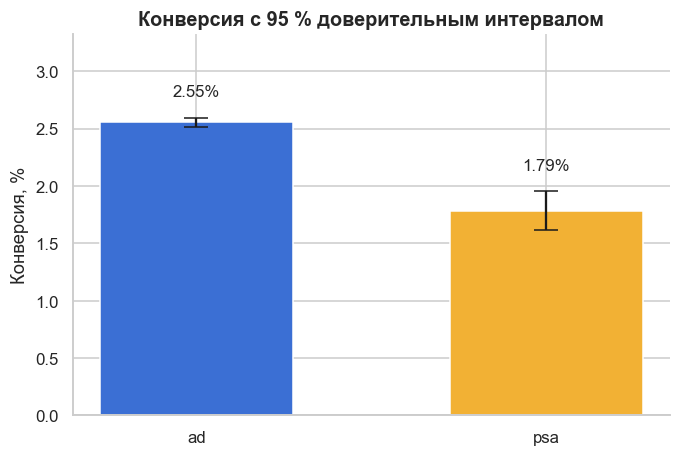

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
values = [p_ad * 100, p_psa * 100]
errors = [z_alpha * np.sqrt(p * (1 - p) / n) * 100 for p, n in ((p_ad, n_ad), (p_psa, n_psa))]
bars = ax.bar(['ad', 'psa'], values, yerr=errors, capsize=8,
              color=['#3b6fd4', '#f2b134'], width=0.55)
ax.bar_label(bars, fmt='%.2f%%', padding=12, fontsize=11)
ax.set(title='Конверсия с 95 % доверительным интервалом', ylabel='Конверсия, %', xlabel='')
ax.set_ylim(0, max(values) * 1.3)
sns.despine()
plt.show()

Конверсия в рекламной группе выше на **0.77 п.п.** (2.55 % против 1.79 %), относительный рост — **+43 %**, 95 % ДИ [0.60; 0.94] п.п. не включает ноль, p ≈ 4.8·10⁻¹⁸.

При этом h Кохена = 0.053 — по стандартным порогам это малый эффект. Оба взгляда верны: в абсолютных процентных пунктах прирост небольшой, но относительно низкой базовой конверсии он существенный.

## 5. Баланс групп по показам

In [8]:
ads = df.groupby('group')['total_ads'].agg(['mean', 'std', 'count'])
display(ads)

u_stat, p_mw = stats.mannwhitneyu(df.loc[df.group == 'ad', 'total_ads'],
                                  df.loc[df.group == 'psa', 'total_ads'])
smd = ((ads.loc['ad', 'mean'] - ads.loc['psa', 'mean'])
       / np.sqrt((ads.loc['ad', 'std'] ** 2 + ads.loc['psa', 'std'] ** 2) / 2))
print(f'Манн—Уитни: p = {p_mw:.2e}')
print(f'стандартизованная разница средних (SMD): {smd:.4f}')

,mean,std,count
group,,,
ad,24.8234,43.7505,564577
psa,24.7611,42.8607,23524


Манн—Уитни: p = 4.69e-11
стандартизованная разница средних (SMD): 0.0014


Среднее число показов почти одинаково: 24.82 против 24.76, SMD = 0.0014 — это отличный баланс (порог 0.1). При этом p-value Манна—Уитни около 5·10⁻¹¹: на 588 тысячах наблюдений значимым становится различия в сотые доли. Поэтому баланс оцениваем по размеру эффекта, а не по p-value.

## 6. Сегменты по дням недели

In [9]:
rows = []
for day, subset in df.groupby('day'):
    a = subset[subset['group'] == 'ad']['converted']
    p = subset[subset['group'] == 'psa']['converted']
    d = a.mean() - p.mean()
    se_d = np.sqrt(a.mean() * (1 - a.mean()) / len(a) + p.mean() * (1 - p.mean()) / len(p))
    rows.append({'day': day, 'n_ad': len(a), 'n_psa': len(p),
                 'ad_pct': a.mean() * 100, 'psa_pct': p.mean() * 100,
                 'diff_pp': d * 100, 'ci_low': (d - z_alpha * se_d) * 100,
                 'ci_high': (d + z_alpha * se_d) * 100,
                 'p_value': 2 * stats.norm.sf(abs(d / se_d))})
segments = pd.DataFrame(rows)

segments = segments.sort_values('p_value').reset_index(drop=True)
m = len(segments)
segments['p_holm'] = [(m - i) * p for i, p in enumerate(segments['p_value'])]
segments['p_holm'] = segments['p_holm'].cummax().clip(upper=1)
display(segments.round(4))

,day,n_ad,n_psa,ad_pct,psa_pct,diff_pp,ci_low,ci_high,p_value,p_holm
0,Tuesday,74572,2907,3.0440,1.4448,1.5992,1.1483,2.0502,0.0000,0.0000
1,Wednesday,77418,3490,2.5356,1.5759,0.9597,0.5319,1.3874,0.0000,0.0001
2,Monday,83571,3502,3.3241,2.2559,1.0683,0.5617,1.5749,0.0000,0.0002
3,Saturday,78802,2858,2.1307,1.3996,0.7311,0.2888,1.1734,0.0012,0.0048
4,Friday,88805,3803,2.2465,1.6303,0.6162,0.2021,1.0303,0.0035,0.0106
5,Sunday,82332,3059,2.4620,2.0595,0.4025,-0.1118,0.9168,0.1251,0.2501
6,Thursday,79077,3905,2.1637,2.0230,0.1407,-0.3124,0.5937,0.5428,0.5428


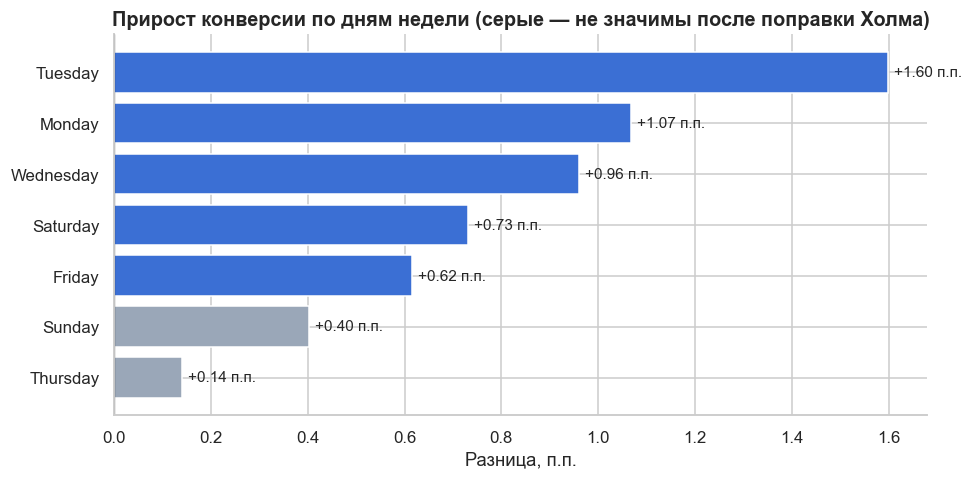

In [10]:
plot = segments.sort_values('diff_pp')
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ['#3b6fd4' if p < 0.05 else '#9aa7b8' for p in plot['p_holm']]
bars = ax.barh(plot['day'], plot['diff_pp'], color=colors)
ax.axvline(0, color='#333', linewidth=0.8)
ax.bar_label(bars, fmt='%+.2f п.п.', padding=4, fontsize=10)
ax.set(title='Прирост конверсии по дням недели (серые — не значимы после поправки Холма)',
       xlabel='Разница, п.п.', ylabel='')
sns.despine()
plt.tight_layout()
plt.show()

Эффект есть в большинстве дней, но его размер колеблется от +0.14 до +1.60 п.п. После поправки Холма значимы понедельник, вторник, среда, суббота и пятница; четверг и воскресенье — нет. Разброс по дням скорее отражает разную аудиторию и активность, чем реальную «силу дня»: данных для причинного вывода о дне недели нет.

## 7. Сегменты по времени суток

In [11]:
df['time_bucket'] = pd.cut(df['hour'], [-1, 5, 11, 17, 23],
                           labels=['ночь 0–5', 'утро 6–11', 'день 12–17', 'вечер 18–23'])
rows = []
for bucket, subset in df.groupby('time_bucket', observed=True):
    a = subset[subset['group'] == 'ad']['converted']
    p = subset[subset['group'] == 'psa']['converted']
    d = a.mean() - p.mean()
    se_d = np.sqrt(a.mean() * (1 - a.mean()) / len(a) + p.mean() * (1 - p.mean()) / len(p))
    rows.append({'bucket': bucket, 'n_ad': len(a), 'n_psa': len(p),
                 'diff_pp': d * 100, 'ci_low': (d - z_alpha * se_d) * 100,
                 'ci_high': (d + z_alpha * se_d) * 100,
                 'p_value': 2 * stats.norm.sf(abs(d / se_d))})
hours = pd.DataFrame(rows).sort_values('p_value').reset_index(drop=True)
m = len(hours)
hours['p_holm'] = [(m - i) * p for i, p in enumerate(hours['p_value'])]
hours['p_holm'] = hours['p_holm'].cummax().clip(upper=1)
display(hours.round(4))

,bucket,n_ad,n_psa,diff_pp,ci_low,ci_high,p_value,p_holm
0,ночь 0–5,19102,735,1.2094,0.8968,1.5219,0.0000,0.0000
1,утро 6–11,136526,5727,0.8589,0.5604,1.1574,0.0000,0.0000
2,день 12–17,246925,10914,0.7511,0.4796,1.0226,0.0000,0.0000
3,вечер 18–23,162024,6148,0.6777,0.3134,1.0420,0.0003,0.0003


Во всех четырёх интервалах эффект положительный и значимый после поправки Холма. Самый большой — ночью (+1.21 п.п.), но там мало пользователей и широкий интервал; днём и вечером эффект около +0.7 п.п. при больших выборках.

## 8. Доза показов и конверсия

,users,conversion,conversion_pct
dose,,,
1–5,169962,0.0025,0.2512
6–15,146101,0.0061,0.6051
16–40,160056,0.0183,1.8350
41+,88458,0.1150,11.5026


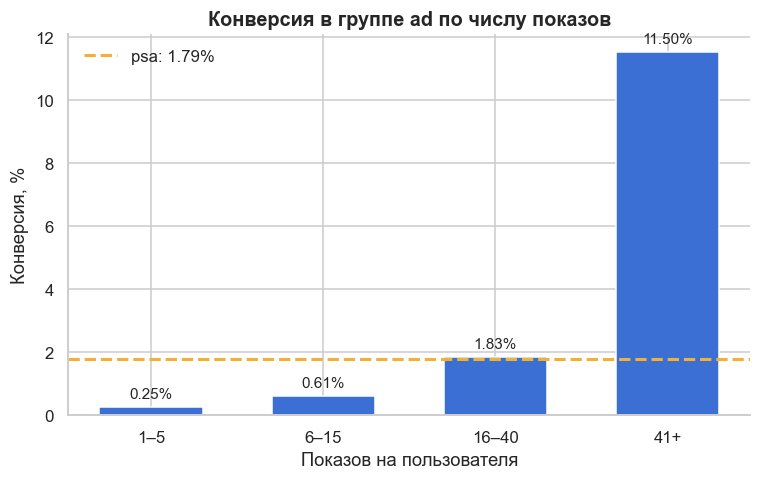

In [12]:
ad = df[df['group'] == 'ad'].copy()
ad['dose'] = pd.cut(ad['total_ads'], [0, 5, 15, 40, 10**6],
                    labels=['1–5', '6–15', '16–40', '41+'])
dose = ad.groupby('dose', observed=True)['converted'].agg(users='size', conversion='mean')
dose['conversion_pct'] = dose['conversion'] * 100
display(dose)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(dose.index.astype(str), dose['conversion_pct'], color='#3b6fd4', width=0.6)
ax.bar_label(bars, fmt='%.2f%%', padding=4, fontsize=10)
ax.axhline(p_psa * 100, color='#f2b134', linestyle='--', linewidth=2,
           label=f'psa: {p_psa:.2%}')
ax.set(title='Конверсия в группе ad по числу показов', ylabel='Конверсия, %', xlabel='Показов на пользователя')
ax.legend(frameon=False)
sns.despine()
plt.show()

Конверсия растёт с числом показов: 0.25 % в группах 1–5 показов, 11.5 % — при 41+. Это сильная связь, но **не доказательство причинности**: показы не назначались случайно, их больше получают активные и вовлечённые пользователи. Переменная пост-обработки, поэтому использовать её как эффект нельзя — только как описательную закономерность и материал для отдельного эксперимента.

## 9. Чувствительность

In [13]:
mde_observed = (z_alpha + z_beta) * se
print(f'фактический MDE при текущей выборке: {mde_observed * 100:.2f} п.п.')
print(f'наблюдаемый эффект: {diff * 100:.2f} п.п. — в {diff / mde_observed:.1f} раза больше MDE')

фактический MDE при текущей выборке: 0.25 п.п.
наблюдаемый эффект: 0.77 п.п. — в 3.1 раза больше MDE


## 10. Ограничения

- Нет выручки и стоимости привлечения: нельзя посчитать ARPU, ROI и окупаемость.
- Нет guardrail-метрики: проверить, не выросла ли нагрузка на поддержку или число возвратов, невозможно.
- Разделение 96/4, а не 50/50: контрольная группа небольшая, поэтому эффект в узких сегментах измеряется с большей погрешностью.
- «Число показов» — переменная после рандомизации; связь с конверсией описательная.
- Нет временных меток пользователя: нельзя проверить стабильность эффекта во времени и провести A/A-тест.
- Данные охватывают одну рекламную кампанию: переносить вывод на другие кампании и каналы нельзя.

## 11. Итог и решение

- Дизайн: разделение 96/4 — это holdout-дизайн, а не SRM-ошибка; доля `psa` стабильна по дням (3.5–4.7 %).
- Баланс по показам хороший: SMD = 0.0014, средние 24.82 и 24.76.
- Первичная метрика: конверсия 2.55 % против 1.79 %, разница **+0.77 п.п.**, 95 % ДИ [0.60; 0.94], p ≈ 4.8·10⁻¹⁸.
- Эффект устойчив по дням и времени суток, но по размеру малый (h = 0.053): в абсолюте это меньше процента, в относительных значениях — +43 % к конверсии.
- Зависимость от числа показов сильная, но причинной её назвать нельзя.

**Решение:** рекламную кампанию можно масштабировать при условии, что стоимость дополнительной конверсии укладывается в экономику; для окончательного решения нужны выручка и CAC. Дополнительно стоит запустить отдельный тест с контролем дозы показов, чтобы отделить эффект рекламы от эффекта активной аудитории.